# Relatório do pipeline DCJ (SIM x SIH)
Este notebook **só lê e mostra** resultados. Gere-os antes no terminal:

```
python -m dcj
```

In [41]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from dcj.configuracao import carregar_configuracao

PASTA = Path(r"C:\Users\isabe\Downloads\projeto_dcj\dados_rs_drp\resultados")

def ler(nome: str, **argumentos) -> pd.DataFrame:
    return pd.read_csv(PASTA / f"{nome}.csv", **argumentos)

print("Resultados em:", PASTA)

Resultados em: C:\Users\isabe\Downloads\projeto_dcj\dados_rs_drp\resultados


In [42]:
import pandas as pd
from dcj.fonte_pysus import obter_obitos_do_pysus

# 1. O que o PySUS entrega AGORA?
print("--- Baixando do PySUS novamente ---")
novo = obter_obitos_do_pysus("RS", 2019)
print("Tamanho do download novo:", len(novo))
print("Top 5 prefixos de UF:", novo["CODMUNRES"].astype(str).str[:2].value_counts().head(5).to_dict())

# 2. O que tem no arquivo em disco?
print("\n--- Lendo o arquivo em disco ---")
disco = pd.read_parquet(r"C:\Users\isabe\Downloads\projeto_dcj\dados_rs_drp\sim\sim_rs_2019.parquet")
print("Tamanho do arquivo em disco:", len(disco))
print("Top 5 prefixos de UF:", disco["CODMUNRES"].astype(str).str[:2].value_counts().head(5).to_dict())

--- Baixando do PySUS novamente ---


c:\Users\isabe\Downloads\projeto_dcj\projeto_dcj\dcj\fonte_pysus.py:87: PySUSWarning: pysus.sim() is deprecated and will be removed. Use the origin-namespaced API instead, e.g. pysus.ftp.sim(...), pysus.dadosgov.sim(...), or pysus.saude.sim(...). Behavior is unchanged.
  "pysus.sim (legado)": lambda: _importar_pysus().sim(sigla_uf, ano, as_dataframe=True),
DORS2019.parquet: 0.00B [00:00, ?B/s]
Mortalidade_Geral_2019.parquet: 0.00B [00:00, ?B/s]


Tamanho do download novo: 178476
Top 5 prefixos de UF: {'43': 178476}

--- Lendo o arquivo em disco ---
Tamanho do arquivo em disco: 2312
Top 5 prefixos de UF: {'43': 2312}


## 1. Funil de ingestão dos óbitos
Quanto do que foi baixado é residente da UF e não duplicado.

,etapa,registros,percentual_do_bruto,removidos_na_etapa
0,1. Arquivos brutos,14092,100.00,0
1,2. Residentes da UF (prefixo 43),14092,100.00,0
2,3. Sem duplicatas,7052,50.04,7040
3,4. Data na janela 2017-2022,7052,50.04,0


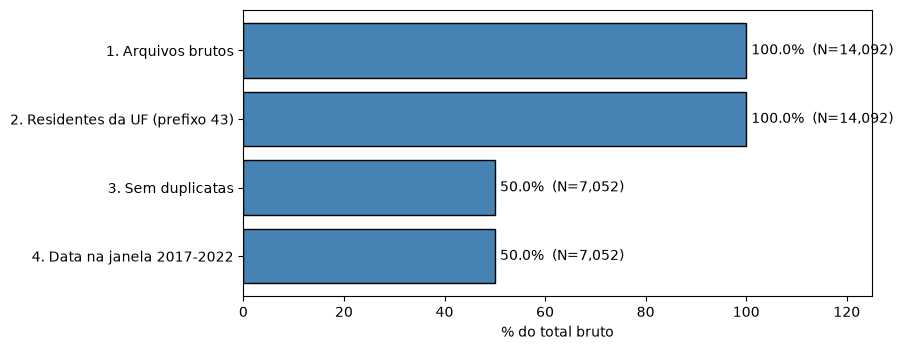

In [43]:
funil = ler("funil_obitos")
display(funil)

figura, eixo = plt.subplots(figsize=(9, 3.6))
eixo.barh(funil["etapa"][::-1], funil["percentual_do_bruto"][::-1], color="#4682b4", edgecolor="black")
for posicao, (percentual, total) in enumerate(zip(funil["percentual_do_bruto"][::-1], funil["registros"][::-1])):
    eixo.text(percentual + 1, posicao, f"{percentual:.1f}%  (N={total:,})", va="center")
eixo.set_xlim(0, 125)
eixo.set_xlabel("% do total bruto")
plt.tight_layout()
plt.show()

## 2. Pareamento e cobertura por ano
Valores longe de 1,0 em `*_sobre_mediana` indicam ano com cobertura anômala.

In [44]:
display(ler("pareamento_resumo", index_col=0))
display(ler("cobertura_por_ano", index_col=0))

,valor
pares_candidatos,326
apos_internacao_antes_do_obito,286
pares_finais,176


,obitos,internacoes,obitos_sobre_mediana,internacoes_sobre_mediana
2016,0,790,0.00,1.00
2017,843,1089,0.73,1.38
2018,1050,787,0.91,1.00
2019,1157,716,1.01,0.91
2020,1149,750,1.00,0.95
2021,1300,861,1.13,1.09
2022,1553,985,1.35,1.25


## 3. Escore de suspeição
Com poucos pares as taxas são instáveis: veja o intervalo de confiança e a taxa por 100 internações.

In [45]:
display(ler("escore_por_periodo", index_col=0))
display(ler("escore_taxa_normalizada"))
display(ler("escore_sensibilidade_desempate"))
display(ler("escore_sensibilidade_faixa_etaria"))
display(ler("captura_recaptura_sensibilidade"))

,total_de_pares,escore_medio,sinalizados,taxa_percentual,intervalo_de_confianca_95
periodo,,,,,
Pandemia (2020-2022),112,47.142857,47,42.0,33.2-51.2
Pré-pandemia (2017-2019),64,45.625000,24,37.5,26.7-49.7


,periodo_da_internacao,internacoes,sinalizados,por_100_internacoes
0,Pré-pandemia (2017-2019),2592,25,0.96
1,Pandemia (2020-2022),2596,45,1.73


,criterio_de_desempate,pares,sinalizados,mediana_de_dias_ate_o_obito
0,ultima,176,71,31.0
1,primeira,174,68,37.0


,cenario,faixa_etaria,pares,sinalizados
0,configurada,30-64,176,71
1,pico_de_notificacoes_do_boletim,55-74,176,79
2,sem_restricao_de_idade,0-120,176,136


,cenario,total_sinan,total_sim,em_ambas,observados,chapman,ic95_inferior,ic95_superior,razao_0.5,razao_1,razao_2,razao_3
0,todas (45) | chave forte observada,45,44,10,79,187,106,268,133,187,295,404
1,todas (45) | chave fraca descontando o acaso,45,44,15,74,128,89,168,101,128,183,237
2,todas (45) | chave forte extrapolada p/ data a...,45,44,25,64,79,66,91,71,79,93,108
3,CLASSI_FIN=1 (28) | chave forte observada,28,44,8,64,144,77,211,104,144,224,304
4,CLASSI_FIN=1 (28) | chave fraca descontando o ...,28,44,12,60,99,66,132,80,99,139,178
5,CLASSI_FIN=1 (28) | chave forte extrapolada p/...,28,44,16,56,76,58,94,66,76,96,115


In [46]:
colunas = ["data_internacao", "data_obito", "dias_ate_obito", "idade_anos", "diagnostico_principal",
           "causa_basica", "municipio", "escore_dcj", "periodo"]
casos = ler("casos_sinalizados")
display(casos[[coluna for coluna in colunas if coluna in casos.columns]])

,data_internacao,data_obito,dias_ate_obito,idade_anos,diagnostico_principal,causa_basica,municipio,escore_dcj,periodo
0,2016-07-03,2017-03-18,258,78.0,G311,G319,430850,70,Pré-pandemia (2017-2019)
1,2017-03-04,2017-03-05,1,62.0,G936,G934,431490,70,Pré-pandemia (2017-2019)
2,2017-03-13,2017-04-05,23,72.0,G310,G319,430915,70,Pré-pandemia (2017-2019)
3,2017-03-18,2017-03-18,0,63.0,G936,G931,431560,70,Pré-pandemia (2017-2019)
4,2017-06-19,2017-07-06,17,50.0,G318,A810,430510,70,Pré-pandemia (2017-2019)
...,...,...,...,...,...,...,...,...,...
66,2022-06-22,2022-06-22,0,64.0,G935,G934,432150,70,Pandemia (2020-2022)
67,2022-07-02,2022-09-22,82,93.0,G318,G319,431490,70,Pandemia (2020-2022)
68,2022-08-01,2022-08-04,3,74.0,G318,F03,431490,70,Pandemia (2020-2022)
69,2022-08-27,2022-09-09,13,85.0,G318,F03,431490,70,Pandemia (2020-2022)


## 4. Validação
`observado` é o número de pares do pipeline; `media_ao_acaso` e `percentil_95_ao_acaso` são o que o acaso produz nos mesmos blocos. Se `p_valor_unilateral` da última linha não for pequeno, os pares finais não se distinguem do acaso.

In [47]:
display(ler("permutacao"))
display(ler("concordancia", index_col=0))

,etapa,observado,media_ao_acaso,percentil_95_ao_acaso,excesso,p_valor_unilateral
0,bloco + dia/mês iguais,326,53.15,66,272.85,0.0005
1,+ internação <= óbito,286,30.66,40,255.34,0.0005
2,+ 1:1 (pares finais),176,29.04,37,146.96,0.0005


,valor
pares,176.0000
concordancia_observada,0.3068
kappa_4_digitos,0.2124
kappa_3_digitos,0.3683
kappa_exploratorio_f03_igual_g31,0.7164


## 5. Referência: Boletim Epidemiológico DCJ (SVS/MS, vol. 53, n. 39, 2022)
A faixa 30-64 do escore exclui cerca de 44% das notificações suspeitas (65 anos ou mais; p. 21). A tabela de sensibilidade (seção 3) mostra quantos sinalizados mudam com a faixa 55-74 (p. 18). Óbitos A81.0 abaixo de 1 a 2 por milhão por ano (p. 12) podem indicar subnotificação ou cobertura incompleta do SIM.

In [48]:
arquivo = PASTA / "obitos_a810_vs_esperado.csv"
if arquivo.exists():
    display(pd.read_csv(arquivo, index_col=0))
else:
    print("Rode `python -m dcj --etapa validacao --populacao N` para gerar esta tabela.")

,obitos_a810_observados,esperado_minimo,esperado_maximo,abaixo_do_minimo_esperado
ano,,,,
2017,6,10.9,21.8,True
2018,9,10.9,21.8,True
2019,9,10.9,21.8,True
2020,7,10.9,21.8,True
2021,7,10.9,21.8,True
2022,6,10.9,21.8,True


## 6. Cruzamento exploratório com o SINAN
Chave fraca (ano de nascimento, sexo, município): use para revisão manual, não para proporções.

In [49]:
arquivo_sinan = PASTA / "sinan_resumo.csv"
if arquivo_sinan.exists():
    display(pd.read_csv(arquivo_sinan, index_col=0))
else:
    print("Sem SINAN: coloque sinan/sinan_rs_a81x_todos_anos.parquet e rode --etapa sinan.")

,valor
notificacoes_brutas,45
notificacoes_a81_com_chave_e_sintomas,45
sinan_x_sim_por_chave,179
sinan_x_sim_validos,143
sinan_x_sim_na_janela_de_sobrevida,38
sinan_x_sih_por_chave,145
sinan_x_sih_validos,109


In [50]:
for nome in ("permutacao_sinan", "sinan_perfil_individuos"):
    arquivo = PASTA / f"{nome}.csv"
    if arquivo.exists():
        display(pd.read_csv(arquivo))

,etapa,observado,media_ao_acaso,percentil_95_ao_acaso,excesso,p_valor_unilateral
0,bloco + ano de nascimento iguais,22,22.00,22,0.00,1.0000
1,+ óbito >= primeiros sintomas,22,20.95,22,1.05,0.2054
2,+ óbito em até 1 ano dos sintomas,20,16.40,19,3.60,0.0195
3,+ indivíduos únicos,20,16.40,19,3.60,0.0195


,Unnamed: 0,valor
0,individuos_unicos,38.0
1,idade_media_ao_obito,71.9
2,idade_mediana_ao_obito,74.0
3,sexo_F,22.0
4,sexo_M,16.0
5,causa_A810,18.0
6,causa_G311,14.0
7,causa_G319,3.0
8,causa_A819,2.0
9,causa_G934,1.0


In [51]:
import numpy as np
import pandas as pd
import glob

# 1. Carregar os dados (SIM e SINAN)
arquivos_sim = glob.glob(r"C:\Users\isabe\Downloads\projeto_dcj\dados_rs_drp\sim\sim_rs_*.parquet")
df_sim_total = pd.concat([pd.read_parquet(f) for f in arquivos_sim], ignore_index=True)

arquivos_sinan = glob.glob(r"C:\Users\isabe\Downloads\projeto_dcj\dados_rs_drp\sinan\sinan_rs_*.parquet")
df_sinan = pd.concat([pd.read_parquet(f) for f in arquivos_sinan], ignore_index=True)

# Filtro do SINAN para RS
col_mun = "ID_MN_RESI" if "ID_MN_RESI" in df_sinan.columns else "MUNICIPIO"
df_sinan[col_mun] = df_sinan[col_mun].astype("string").str.replace(r"\.0$", "", regex=True)
df_sinan = df_sinan[df_sinan[col_mun].str.startswith("43", na=False)]

for c in ["CLASSI_FIN", "EVOLUCAO"]:
    if c in df_sinan.columns:
        df_sinan[c] = df_sinan[c].astype("string").str.replace(r"\.0$", "", regex=True)

# 2. Funções do revisor
JANELA_OBITO_DIAS = 30
JANELA_SINTOMA    = (-30, 365)

def _dmy(s):
    if pd.api.types.is_datetime64_any_dtype(s): return s
    s = s.astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(8)
    return pd.to_datetime(s, format="%d%m%Y", errors="coerce")

def _mun6(s): return s.astype("string").str.replace(r"\.0$", "", regex=True).str.strip().str.zfill(6).str[:6]
def _sexo(s): return s.astype("string").str.strip().str.upper().replace({"1": "M", "2": "F"})

def preparar_sinan(df):
    s = df.reset_index(drop=True).copy()
    s["SID"] = s.index
    col_sexo = "CS_SEXO" if "CS_SEXO" in s.columns else "SEXO"
    col_ano = "ANO_NASC_LIMPO" if "ANO_NASC_LIMPO" in s.columns else ("ANO_NASC" if "ANO_NASC" in s.columns else "ANO_NASCIMENTO")
    col_dt_sin = "DT_SIN_PRI" if "DT_SIN_PRI" in s.columns else "DATA_PRIMEIROS_SINTOMAS"
    col_dt_obito = "DT_OBITO" if "DT_OBITO" in s.columns else "DATA_OBITO"
    
    s["MUN6"] = _mun6(s[col_mun])
    s["SEXO"] = _sexo(s[col_sexo])
    s["ANO_N"] = pd.to_numeric(s[col_ano], errors="coerce").astype("Int64")
    s["DT_SIN"] = pd.to_datetime(s[col_dt_sin], errors="coerce")
    s["DT_OBITO_SN"] = pd.to_datetime(s[col_dt_obito], errors="coerce") if col_dt_obito in s.columns else pd.NaT
    return s

def preparar_sim(df):
    d = df.drop_duplicates().reset_index(drop=True).copy()
    d["OID"] = d.index
    d["MUN6"] = _mun6(d["CODMUNRES"])
    d = d[d["MUN6"].str.startswith("43")].copy()
    d["SEXO"] = _sexo(d["SEXO"])
    d["DTN"] = _dmy(d["DTNASC"])
    d["DTO"] = _dmy(d["DTOBITO"])
    d["ANO_N"] = d["DTN"].dt.year.astype("Int64")
    d["E_A81"] = d["CAUSABAS"].astype("string").str.upper().str.startswith("A810").fillna(False)  

    return d

def cruzar(sn, sim):
    m = sim.merge(sn[["SID", "MUN6", "SEXO", "ANO_N", "DT_SIN", "DT_OBITO_SN"]], on=["MUN6", "SEXO", "ANO_N"], how="inner")
    m["DIAS_SINTOMA_OBITO"] = (m["DTO"] - m["DT_SIN"]).dt.days
    lo, hi = JANELA_SINTOMA
    m = m[m["DIAS_SINTOMA_OBITO"].between(lo, hi)].copy()
    m["DELTA_OBITO"] = (m["DTO"] - m["DT_OBITO_SN"].dt.normalize()).dt.days
    ind = "indeterminado (sem DT_OBITO no SINAN)"
    m["CHAVE_OBITO"] = np.select(
        [m["DELTA_OBITO"].isna(), m["DELTA_OBITO"].abs() <= JANELA_OBITO_DIAS],
        [ind, "forte"], default="incompatível")
    return m

# 3. Executa tudo de uma vez
sn  = preparar_sinan(df_sinan)
sim = preparar_sim(df_sim_total)
m = cruzar(sn, sim)

# 4. Auditoria de mascaramento (chave forte)
mascarados_fortes = m[(m["CHAVE_OBITO"] == "forte") & (~m["E_A81"])]
cols_auditoria = ["SID", "MUN6", "SEXO", "ANO_N", "DT_SIN", "DT_OBITO_SN", "DTO", "CAUSABAS"]
tabela_auditoria = mascarados_fortes[cols_auditoria].sort_values("DTO")

tabela_auditoria.to_csv(PASTA / "auditoria_mascaramento_confirmado.csv", index=False)
print(f"Total de casos de mascaramento CONFIRMADOS (chave forte): {len(tabela_auditoria)}")
display(tabela_auditoria)

Total de casos de mascaramento CONFIRMADOS (chave forte): 1


,SID,MUN6,SEXO,ANO_N,DT_SIN,DT_OBITO_SN,DTO,CAUSABAS
167,42,431560,F,1953,2022-09-01,2022-11-05,2022-11-05,G934


In [52]:
# Verifica o nome exato das colunas
print(df_sinan.columns.tolist())

# Se a coluna for DT_OBITO, veja como os valores estão armazenados (antes de tentar converter)
if "DT_OBITO" in df_sinan.columns:
    print("Exemplo de DT_OBITO:", df_sinan["DT_OBITO"].dropna().head(3).tolist())
elif "DATA_OBITO" in df_sinan.columns:
    print("Exemplo de DATA_OBITO:", df_sinan["DATA_OBITO"].dropna().head(3).tolist())
else:
    print("Nenhuma coluna de data de óbito encontrada!")

['ID_AGRAVO', 'ID_MN_RESI', 'CS_SEXO', 'ANO_NASC', 'DT_SIN_PRI', 'DT_NOTIFIC', 'DT_OBITO', 'CLASSI_FIN', 'EVOLUCAO']
Exemplo de DT_OBITO: [datetime.date(2017, 7, 6), datetime.date(2017, 11, 14), datetime.date(2017, 7, 31)]


In [53]:
from dcj.captura_recaptura import DuasListas, montar_tabela_de_sensibilidade

# Dados extraídos do seu pipeline (ajuste se necessário)
listas_todas = DuasListas(total_da_primeira=45, total_da_segunda=44, em_ambas=10)
listas_confirmadas = DuasListas(total_da_primeira=28, total_da_segunda=44, em_ambas=8)

cenarios = {
    "SINAN todas (45)": listas_todas,
    "SINAN confirmadas (28)": listas_confirmadas,
}

tabela_sensibilidade = montar_tabela_de_sensibilidade(cenarios)
display(tabela_sensibilidade)
tabela_sensibilidade.to_csv(PASTA / "captura_recaptura_sensibilidade.csv", index=False)

,cenario,total_sinan,total_sim,em_ambas,observados,chapman,ic95_inferior,ic95_superior,razao_0.5,razao_1,razao_2,razao_3
0,SINAN todas (45),45,44,10,79,187,106,268,133,187,295,404
1,SINAN confirmadas (28),28,44,8,64,144,77,211,104,144,224,304
